# Analyse bivariée et multivariée

## bjectif

Cette étape vise à étudier les relations entre les différentes variables du dataset afin de mieux comprendre les facteurs associés au rendement agricole.

L'analyse portera notamment sur :

- les relations entre variables numériques ;
- les relations entre variables catégorielles et numériques ;
- les éventuelles corrélations entre variables explicatives ;
- l'identification de tendances, groupes ou comportements atypiques ;
- la préparation des variables pertinentes avant la modélisation.


## 1. Analyse des corrélations

Une matrice de corrélation permettra d'étudier les relations linéaires entre les variables numériques.

Elle sera notamment utilisée pour observer les relations entre :

- la pluviométrie ;
- la température ;
- la durée avant récolte ;
- le rendement ;

Une attention particulière sera portée aux variables fortement corrélées entre elles afin de détecter d'éventuels phénomènes de multicolinéarité.


In [14]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

df = pd.read_csv("../data/processed/final_dataset.csv")

numeric_df = df.select_dtypes(include="number")
cat_df = df.select_dtypes(include=["str", "bool"])

display(df.head())

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare,pesticides_tonnes_mean
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816,0.000000
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341,36942.215995
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443,0.000000
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573,40752.554896
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251,35453.212930


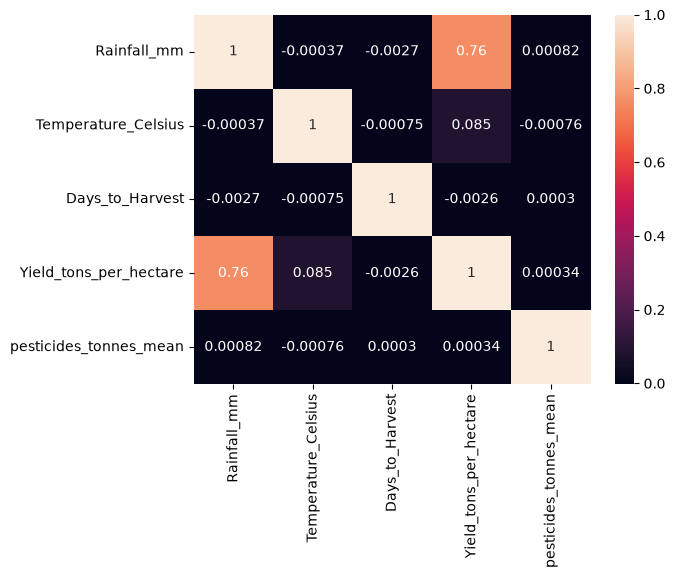

In [15]:
correlation_matrix = numeric_df.corr()

sns.heatmap(correlation_matrix, annot=True)
plt.show()

Nous constatons une corrélation:
- forte entre la *pluviométrie* `rainfall_mm` et le *rendement par hectare* `Yield_tons_per_hectare`.
- Assez légère considérant l'ensemble des corrélation entre *la température* `Temperature_Celsius` et et le *rendement par hectare* `Yield_tons_per_hectare`.

## 2. Analyse des variables catégorielles

L'influence des variables catégorielles sur le rendement sera étudiée à l'aide de représentations adaptées.

Variables concernées :

- Region ;
- Soil_Type ;
- Crop ;
- Weather_Condition ;
- Fertilizer_Used ;
- Irrigation_Used.

Des boxplots serront utilisés pour comparer la distribution du rendement entre les différentes catégories.

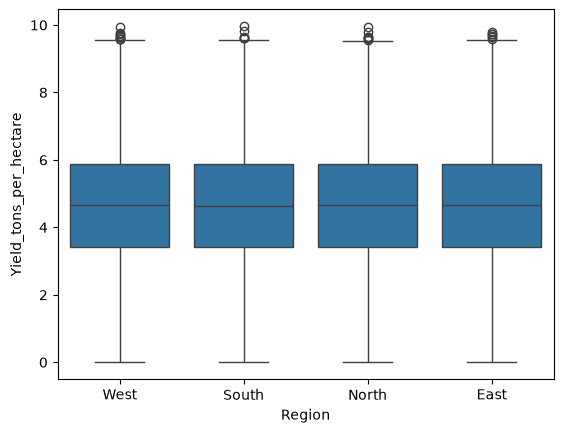

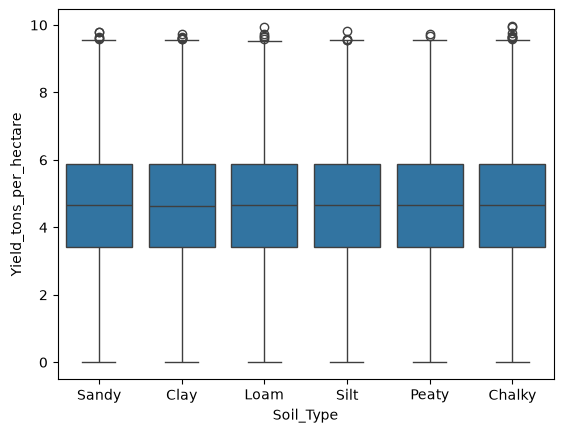

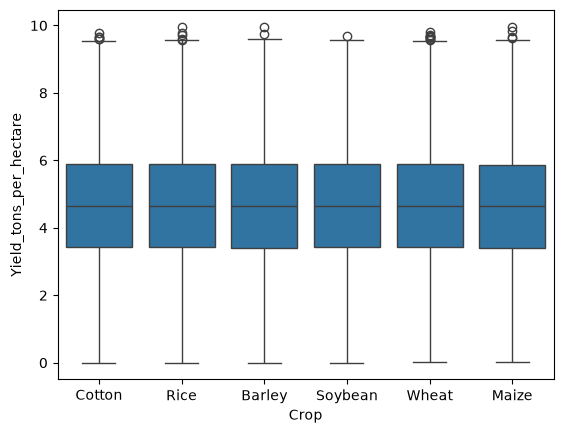

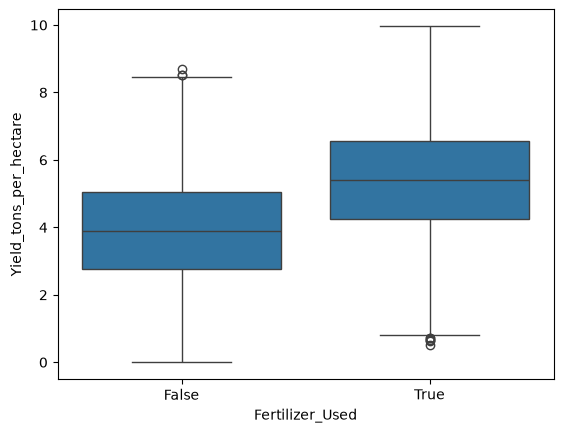

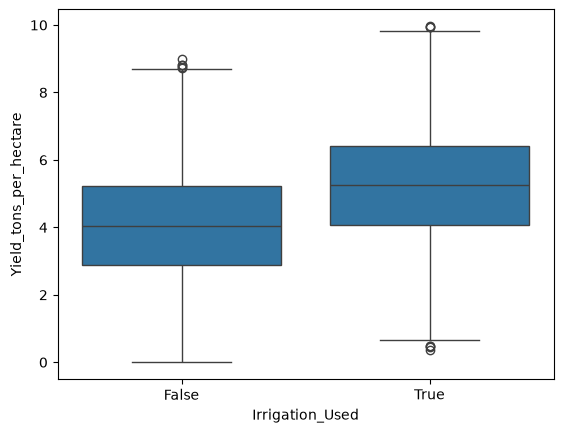

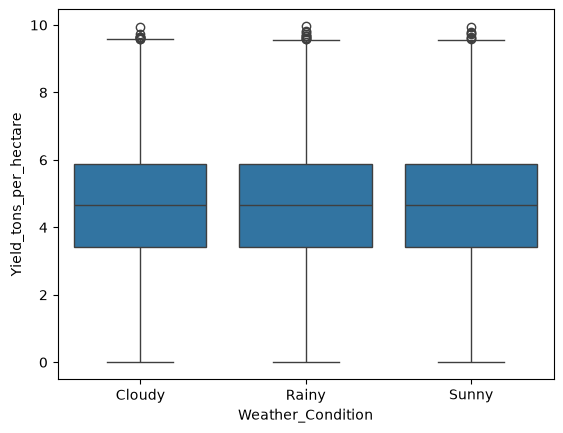

In [16]:
for col in df.columns:
    if df[col].dtype == "str" or df[col].dtype =="bool":
        sns.boxplot(
            data=df,
            x=col,
            y="Yield_tons_per_hectare"
            
        )
        plt.show()

## Interprétation des boxplots des variables catégorielles

Les boxplots permettent de comparer la distribution du rendement agricole en fonction des différentes variables catégorielles du jeu de données. L'analyse porte principalement sur la médiane, la dispersion des valeurs et la présence éventuelle de valeurs atypiques.

###Rendement en fonction de la région

Les différentes régions (`West`, `South`, `North` et `East`) présentent des distributions de rendement très similaires.

Les rendements médians sont quasiment identiques d'une région à l'autre. Les écarts interquartiles ainsi que l'étendue des distributions sont également très proches.

Visuellement, la région ne semble donc pas être associée à une différence marquée de rendement dans ce jeu de données. Des valeurs atypiques sont présentes dans chacune des régions, aussi bien parmi les rendements faibles que parmi les rendements élevés.

Cette représentation seule ne permet toutefois pas de conclure à l'absence d'un effet statistiquement significatif de la région sur le rendement.

---

### Rendement en fonction du type de sol

Les distributions du rendement sont très similaires pour les différents types de sol : `Sandy`, `Clay`, `Loam`, `Silt`, `Peaty` et `Chalky`.

Les médianes sont quasiment identiques et se situent autour de la même valeur. Les écarts interquartiles ainsi que l'étendue des distributions sont également très proches.

Visuellement, le type de sol ne semble donc pas être associé à une différence marquée de rendement dans ce jeu de données. Quelques valeurs atypiques sont présentes pour chaque type de sol, aussi bien dans les valeurs faibles que dans les valeurs élevées.

Cette représentation seule ne permet toutefois pas de conclure à l'absence d'un effet statistiquement significatif du type de sol sur le rendement.

---

### Rendement en fonction de la culture

Les différentes cultures (`Cotton`, `Rice`, `Barley`, `Soybean`, `Wheat` et `Maize`) présentent également des distributions très similaires.

Les rendements médians sont pratiquement identiques entre les cultures et la dispersion des observations reste comparable.

Le graphique ne met donc pas en évidence de culture présentant un rendement globalement supérieur ou inférieur aux autres dans ce dataset.

Cela peut indiquer que la variable `Crop`, prise isolément, ne permet pas d'expliquer une part importante de la variation du rendement. Il sera néanmoins pertinent d'étudier les interactions entre la culture et d'autres variables comme les précipitations, la température, l'irrigation ou l'utilisation de fertilisants.

---

### Rendement en fonction de l'utilisation de fertilisants

Une différence nettement plus importante apparaît lorsque l'on compare les parcelles avec et sans utilisation de fertilisants.

La médiane du rendement est plus élevée lorsque `Fertilizer_Used = True` que lorsque `Fertilizer_Used = False`.

La distribution entière semble également décalée vers des valeurs de rendement plus importantes dans le groupe utilisant des fertilisants.

Cette représentation suggère donc une association positive entre l'utilisation de fertilisants et le rendement agricole.

Cependant, ce graphique ne permet pas à lui seul d'affirmer que les fertilisants sont la cause directe de cette augmentation. D'autres variables peuvent intervenir simultanément dans le niveau de rendement.

---

### Rendement en fonction de l'irrigation

L'utilisation de l'irrigation présente également une différence visible.

Les parcelles pour lesquelles `Irrigation_Used = True` possèdent un rendement médian supérieur à celles pour lesquelles l'irrigation n'est pas utilisée.

Les deux distributions sont clairement décalées, avec des rendements généralement plus élevés pour les observations utilisant l'irrigation.

L'irrigation semble donc être une variable particulièrement intéressante pour expliquer le rendement dans ce jeu de données.

Comme pour les fertilisants, cette observation correspond à une association statistique visible dans les données et ne permet pas encore d'établir une relation de causalité.

---

### Rendement en fonction des conditions météorologiques

Les distributions correspondant aux conditions `Cloudy`, `Rainy` et `Sunny` sont presque identiques.

Les médianes sont très proches et la dispersion des valeurs est comparable dans les trois catégories.

La variable `Weather_Condition` ne semble donc pas, prise isolément, être associée à une variation importante du rendement.

Ce résultat ne signifie toutefois pas nécessairement que les conditions climatiques n'ont aucune influence. Des variables numériques plus précises, comme la température ou la quantité de précipitations, peuvent contenir davantage d'information que cette classification générale de la météo.

---

## Synthèse

L'analyse visuelle des boxplots permet de distinguer deux groupes de variables.

Les variables `Region`, `Soil_Type`, `Crop` et `Weather_Condition` présentent des distributions de rendement très similaires entre leurs différentes catégories. Aucun effet important n'est immédiatement visible sur ces graphiques.

À l'inverse, les variables `Fertilizer_Used` et `Irrigation_Used` montrent des différences beaucoup plus marquées. Les observations utilisant des fertilisants ou l'irrigation présentent des rendements médians plus élevés.

Ces premiers résultats suggèrent donc que l'irrigation et l'utilisation de fertilisants pourraient constituer des variables importantes pour expliquer le rendement. Ces observations devront être complétées par l'analyse des variables numériques, l'étude des interactions entre variables et, si nécessaire, par des tests statistiques afin de déterminer si les différences observées sont statistiquement significatives.


---
### Préparation des variables binaires

`Fertilizer_Used` et `Irrigation_Used` sont des variables booléennes. Pour cette ACP, elles sont encodées en 0/1 et traitées comme des variables numériques. Ce choix permet de les inclure dans le calcul des axes ; leur interprétation reste toutefois celle d’indicateurs binaires encodés.

`Yield_tons_per_hectare` est la variable cible. Elle sera exclue du calcul des axes, puis utilisée après l’ACP pour étudier son association avec les composantes.


In [17]:
#Convertir les indicateurs booléens en variables numériques 0/1 pour l’ACP
numeric_df["Irrigation_Used"] = df["Irrigation_Used"].astype(int)
numeric_df["Fertilizer_Used"] = df["Fertilizer_Used"].astype(int)

display(numeric_df.tail())


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare,pesticides_tonnes_mean,Irrigation_Used,Fertilizer_Used
999764,302.805345,27.987428,76,1.347586,36942.215995,0,0
999765,932.991383,39.661039,93,7.311594,0.000000,0,1
999766,867.362046,24.370042,108,5.763182,0.000000,0,1
999767,492.812857,33.045505,102,2.070159,35453.212930,0,0
999768,180.936180,27.298847,76,2.937243,32765.983322,0,1


---
# 3. Analyse en composantes principales (ACP)

## Pourquoi faire une ACP ?

Dans notre tableau, chaque ligne représente une observation agricole et chaque colonne une variable. L’ACP fabrique de nouvelles variables appelées **composantes principales** ou **axes**. Chaque axe est une combinaison des variables de départ.

Le premier axe, PC1, est la direction dans laquelle les observations sont le plus dispersées. PC2 résume ensuite le plus possible de dispersion restante, tout en étant perpendiculaire à PC1. Les axes suivants poursuivent ce travail.

L’ACP peut aider à comprendre comment les variables évoluent ensemble et si quelques axes résument une grande partie de l’information. Elle ne cherche pas directement quelles variables prédisent le rendement.

## Variables utilisées

Nous faisons l’ACP sur six variables explicatives :

- `Rainfall_mm` : précipitations ;

- `Temperature_Celsius` : température ;
- `Days_to_Harvest` : nombre de jours avant récolte ;
- `pesticides_tonnes_mean` : moyenne historique de pesticides agrégée par culture ;
- `Irrigation_Used` : irrigation, encodée en 0 ou 1 ;
- `Fertilizer_Used` : fertilisant, encodé en 0 ou 1.

Le rendement `Yield_tons_per_hectare` reste à part : il ne participe pas à la construction des axes. Nous regarderons après coup s’il est associé aux scores des observations sur ces axes.

> **Limite sur les pesticides :** la moyenne de pesticides est agrégée par culture puis répétée sur les observations de cette culture. Dans la préparation précédente, les cultures sans correspondance dans les données historiques ont reçu 0. Ce zéro peut donc signifier « pas de correspondance trouvée », et pas forcément « aucun pesticide utilisé ».

Les booléens sont inclus après leur conversion en 0/1. L’ACP les traite alors comme des variables numériques. Dans l’interprétation, il faut se rappeler qu’elles indiquent deux modalités : non (0) et oui (1).

## 3.1 Préparer les colonnes de l’ACP

On rassemble dans `X` les six variables qui vont réellement servir à construire les axes. Le rendement est stocké séparément dans `yield_target` pour pouvoir l’étudier après l’ACP.

Avant de calculer les axes, on vérifie les dimensions de `X`, ses valeurs manquantes et ses statistiques principales. Les contrôles permettent de voir si une colonne manque ou contient une valeur qui empêcherait le calcul.

`np.isfinite` vérifie si chaque valeur est un nombre fini. La soustraction compte combien de valeurs ne sont pas finies : ce nombre doit être égal à zéro.

In [18]:
import numpy as np

active_variables = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Days_to_Harvest",
    "pesticides_tonnes_mean",
    "Irrigation_Used",
    "Fertilizer_Used",
]

#X contient les variables actives de l'ACP
X = numeric_df[active_variables].copy()

#On garde le rendement à part : il ne construit pas les axes
yield_target = df["Yield_tons_per_hectare"]

print("Nombre de lignes et de colonnes dans X :", X.shape)
print("Colonnes utilisées :", X.columns.tolist())

print("Valeurs manquantes par colonne :")
display(X.isna().sum())

#Compter les valeurs NaN, +infini ou -infini
number_of_non_finite_values = X.size - np.isfinite(X).sum().sum()
print("Nombre de valeurs non finies :", number_of_non_finite_values)

print("Résumé des variables :")
display(X.describe().T)

Nombre de lignes et de colonnes dans X : (999769, 6)
Colonnes utilisées : ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest', 'pesticides_tonnes_mean', 'Irrigation_Used', 'Fertilizer_Used']
Valeurs manquantes par colonne :


Rainfall_mm               0
Temperature_Celsius       0
Days_to_Harvest           0
pesticides_tonnes_mean    0
Irrigation_Used           0
Fertilizer_Used           0
dtype: int64

Nombre de valeurs non finies : 0
Résumé des variables :


,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,999769.0,550.077823,259.804329,100.000896,325.062906,550.229205,774.797949,999.998098
Temperature_Celsius,999769.0,27.506079,7.220488,15.000034,21.256078,27.509509,33.754459,39.999997
Days_to_Harvest,999769.0,104.495141,25.953328,60.000000,82.000000,104.000000,127.000000,149.000000
pesticides_tonnes_mean,999769.0,24316.438482,17355.660984,0.000000,0.000000,32765.983322,36942.215995,40752.554896
Irrigation_Used,999769.0,0.499606,0.500000,0.000000,0.000000,0.000000,1.000000,1.000000
Fertilizer_Used,999769.0,0.500056,0.500000,0.000000,0.000000,1.000000,1.000000,1.000000


## 3.2 Centrer-réduire les variables, puis faire l’ACP

Les colonnes n’ont pas toutes la même unité : les précipitations sont en millimètres, les jours avant récolte en jours, et les indicateurs binaires valent 0 ou 1. Si on calculait l’ACP directement sur ces valeurs, une variable avec de grands nombres pourrait peser davantage simplement à cause de son échelle.

`StandardScaler` centre-réduit les colonnes : il soustrait la moyenne puis divise par l’écart-type. Après cette opération, chaque variable a une moyenne proche de 0 et un écart-type proche de 1.

Ensuite, `pca.fit_transform` fait deux choses :

1. `fit` apprend les axes principaux à partir des données centrées-réduites ;
2. `transform` projette chaque observation sur ces axes.

Les coordonnées obtenues sont enregistrées dans `individual_coordinates`. Une ligne correspond à une observation ; les colonnes correspondent aux axes PC1, PC2, etc.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Mettre les variables sur une échelle comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Calculer les axes puis placer chaque observation sur ces axes
pca = PCA()
individual_coordinates = pca.fit_transform(X_scaled)

#Nommer les colonnes des coordonnées : PC1, PC2 et autres
component_names = [f"PC{i}" for i in range(1, pca.n_components_ + 1)]
pc_scores_df = pd.DataFrame(
    individual_coordinates,
    columns=component_names,
    index=X.index,
)

print("Moyenne des colonnes centrées-réduites :")
print(np.round(X_scaled.mean(axis=0), 6))
print("Écart-type des colonnes centrées-réduites :")
print(np.round(X_scaled.std(axis=0), 6))

Moyenne des colonnes centrées-réduites :
[ 0.  0. -0.  0. -0.  0.]
Écart-type des colonnes centrées-réduites :
[1. 1. 1. 1. 1. 1.]


## 3.3 Combien de variance chaque axe résume-t-il ?

La **variance** décrit la dispersion des observations. Une valeur propre indique la quantité de variance portée par un axe. Le ratio de variance expliquée exprime cette quantité en proportion de la variance totale.

Par exemple, si un axe explique 16 %, cela signifie qu’il résume 16 % de la dispersion totale des six variables analysées. La variance cumulée additionne les parts des premiers axes : PC1 + PC2, puis PC1 + PC2 + PC3, etc.

On regarde ces valeurs pour savoir si quelques axes suffisent à représenter les données. Si les premiers axes expliquent peu de variance, la projection en deux dimensions sera utile pour visualiser, mais elle laissera de côté une grande partie de l’information.

In [20]:
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = variance_ratio.cumsum()

variance_table = pd.DataFrame({
    "Axe": component_names,
    "Valeur propre": pca.explained_variance_,
    "Variance expliquée (%)": variance_ratio * 100,
    "Variance cumulée (%)": cumulative_variance * 100,
})

display(variance_table.round(3))

,Axe,Valeur propre,Variance expliquée (%),Variance cumulée (%)
0,PC1,1.003,16.722,16.722
1,PC2,1.003,16.712,33.434
2,PC3,1.001,16.681,50.115
3,PC4,1.000,16.666,66.781
4,PC5,0.997,16.617,83.398
5,PC6,0.996,16.602,100.000


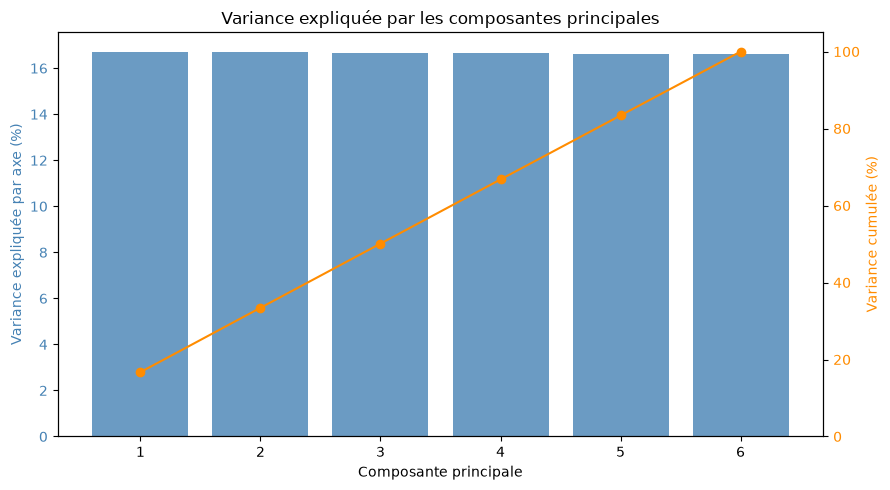

In [21]:
#Les barres montrent la variance expliquée par chaque axe
#La courbe montre la variance cumulée quand on ajoute les axes
fig, ax1 = plt.subplots(figsize=(9, 5))
axes = np.arange(1, len(variance_ratio) + 1)

ax1.bar(axes, variance_ratio * 100, color="steelblue", alpha=0.8)
ax1.set_xlabel("Composante principale")
ax1.set_ylabel("Variance expliquée par axe (%)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.set_xticks(axes)

ax2 = ax1.twinx()
ax2.plot(axes, cumulative_variance * 100, color="darkorange", marker="o")
ax2.set_ylabel("Variance cumulée (%)", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")
ax2.set_ylim(0, 105)

plt.title("Variance expliquée par les composantes principales")
plt.tight_layout()
plt.show()

### Comment lire le graphique ?

Le premier point correspond à PC1 seul. Le deuxième correspond à PC1 et PC2 réunis. Le troisième ajoute PC3, et ainsi de suite.

Une courbe qui monte vite signifie que quelques axes résument beaucoup de dispersion. Une courbe qui monte plus régulièrement signifie qu’il faut conserver plusieurs axes pour représenter les données. Une valeur propre proche de 1 n’est pas une note de qualité : dans cette ACP à six variables standardisées, cela signifie qu’un axe porte environ une part de variance sur six.

## 3.4 Quelles variables construisent les axes ?

Pour donner un sens aux axes, on regarde deux tableaux complémentaires.

**Les coordonnées** indiquent le sens de la relation entre une variable de départ et un axe. Ici, elles sont calculées comme des corrélations : une coordonnée positive signifie que les valeurs élevées de la variable vont généralement avec des scores élevés sur l’axe ; une coordonnée négative signifie qu’elles vont plutôt avec des scores faibles. Une valeur proche de zéro indique une relation faible avec cet axe.

**Les contributions** indiquent quelle part de la construction d’un axe vient de chaque variable. Pour un axe donné, les contributions des six variables totalisent 100 %. Une contribution forte signifie que la variable aide beaucoup à définir cet axe.

Les deux informations ne répondent donc pas à la même question : la contribution mesure l’importance dans la construction de l’axe ; le signe de la coordonnée indique dans quel sens la variable est liée à l’axe. Le signe général d’un axe est arbitraire : si tous les signes d’un axe étaient inversés, l’interprétation resterait la même.

In [22]:
#Mettre les variables standardisées dans un tableau pandas
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=active_variables,
    index=X.index,
)

first_axes = ["PC1", "PC2", "PC3"]

#Calculer la corrélation de chaque variable avec les axes
#Ces corrélations sont les coordonnées des variables sur les axes
variables_and_axes = pd.concat(
    [X_scaled_df, pc_scores_df[first_axes]],
    axis=1,
)
coordinates_table = variables_and_axes.corr().loc[active_variables, first_axes]

#Contribution = coordonnées au carré, divisées par la valeur propre de l'axe
#Le résultat est exprimé en pourcentage
contributions_table = coordinates_table ** 2
for position, axis in enumerate(first_axes):
    contributions_table[axis] = (
        contributions_table[axis] / pca.explained_variance_[position] * 100
    )

print("Coordonnées des variables (corrélation avec les axes) :")
display(coordinates_table.round(3))

print("Contribution de chaque variable aux trois premiers axes (%) :")
display(contributions_table.round(1))

Coordonnées des variables (corrélation avec les axes) :


,PC1,PC2,PC3
Rainfall_mm,-0.337,-0.669,-0.154
Temperature_Celsius,0.507,-0.092,-0.560
Days_to_Harvest,-0.193,0.725,-0.070
pesticides_tonnes_mean,-0.209,-0.097,0.304
Irrigation_Used,0.329,-0.096,0.750
Fertilizer_Used,0.666,-0.041,0.053


Contribution de chaque variable aux trois premiers axes (%) :


,PC1,PC2,PC3
Rainfall_mm,11.3,44.7,2.4
Temperature_Celsius,25.6,0.8,31.4
Days_to_Harvest,3.7,52.5,0.5
pesticides_tonnes_mean,4.3,0.9,9.3
Irrigation_Used,10.8,0.9,56.2
Fertilizer_Used,44.2,0.2,0.3


### Exemple de lecture

Supposons qu’une variable ait une coordonnée de `+0,70` sur PC2 : les observations avec une valeur élevée de cette variable ont généralement un score plus élevé sur PC2. Si une autre variable a une coordonnée de `−0,65`, elle évolue plutôt dans le sens opposé sur cet axe.

Si ces variables contribuent aussi beaucoup à PC2, elles aident à définir l’axe. Cela ne prouve pas qu’elles causent l’une l’autre, ni qu’elles causent le rendement.

### Cercle des corrélations : lire les variables sur PC1 et PC2

Le cercle dessine les coordonnées des variables sur les deux premiers axes. Chaque flèche part du centre : sa position horizontale correspond à PC1, et sa position verticale à PC2.

- Une flèche orientée vers la droite est positivement associée à PC1 ; vers la gauche, négativement.
- Une flèche orientée vers le haut est positivement associée à PC2 ; vers le bas, négativement.
- Deux flèches pointant dans une direction proche suggèrent une association positive sur ce plan. Des flèches en sens opposé suggèrent une association négative.
- Une flèche proche du bord du cercle est bien représentée par ces deux axes. Une flèche proche du centre l’est moins.

Le cercle ne montre que PC1 et PC2. Comme ces axes résument ici environ un tiers de la variance, il faut le lire comme une vue partielle.

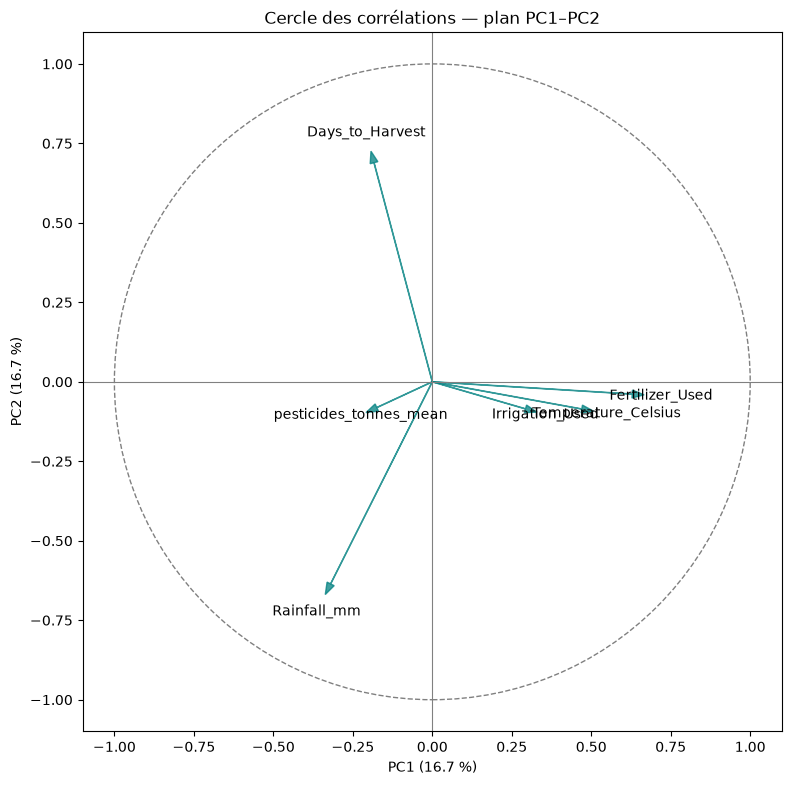

In [23]:

#Le cercle et les flèches gardent le même style que dans le notebook précédent
fig, ax = plt.subplots(figsize=(8, 8))

unit_circle = plt.Circle((0, 0), 1, color="grey", fill=False, linestyle="--")
ax.add_patch(unit_circle)
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)

for variable in active_variables:
    x_coord = coordinates_table.loc[variable, "PC1"]
    y_coord = coordinates_table.loc[variable, "PC2"]
    ax.arrow(0, 0, x_coord, y_coord, color="teal", alpha=0.75,
             head_width=0.025, length_includes_head=True)
    ax.text(x_coord * 1.08, y_coord * 1.08, variable, ha="center", va="center")

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(f"PC1 ({variance_ratio[0] * 100:.1f} %)")
ax.set_ylabel(f"PC2 ({variance_ratio[1] * 100:.1f} %)")
ax.set_title("Cercle des corrélations — plan PC1–PC2")
plt.tight_layout()
plt.show()

## 3.5 Où se trouvent les observations ?

Les **individus** sont les lignes du dataset. `individual_coordinates` contient leurs coordonnées sur tous les axes. Pour les dessiner, on ne garde ici que PC1 et PC2 : chaque point représente une observation agricole.

On colore les points selon `Crop` afin de regarder si les cultures occupent des zones différentes. `Crop` sert uniquement à colorer le graphique : cette colonne n’a pas servi à calculer l’ACP.

Le dataset contient presque un million d’observations. Si on les affiche toutes, les points se superposent beaucoup. On tire donc un échantillon aléatoire de 15 000 lignes pour le graphique. L’ACP et les calculs précédents utilisent toujours toutes les observations ; seul le dessin utilise l’échantillon.

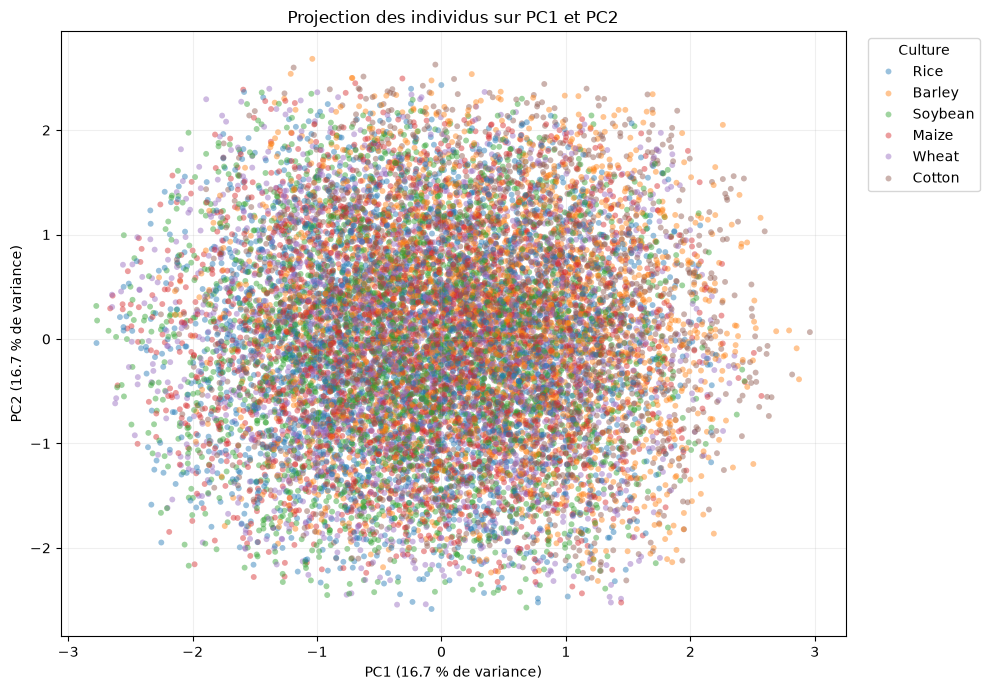

In [24]:
#Créer le tableau des points à afficher sur les deux premiers axes.
individuals_df = pc_scores_df[["PC1", "PC2"]].copy()
individuals_df["Crop"] = df["Crop"].astype(str)

#Garder un échantillon aléatoire pour éviter de surcharger le graphique.
plot_sample = individuals_df.sample(
    n=min(15000, len(individuals_df)),
    random_state=42,
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_sample,
    x="PC1",
    y="PC2",
    hue="Crop",
    alpha=0.45,
    s=18,
    linewidth=0,
)
plt.xlabel(f"PC1 ({variance_ratio[0] * 100:.1f} % de variance)")
plt.ylabel(f"PC2 ({variance_ratio[1] * 100:.1f} % de variance)")
plt.title("Projection des individus sur PC1 et PC2")
plt.legend(title="Culture", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Comment lire la projection ?

On regarde si les couleurs forment des zones séparées ou si elles se mélangent. Dans le graphique obtenu, les cultures se recouvrent fortement : le plan PC1–PC2 ne fait pas apparaître de groupes nettement séparés par culture.

Ce résultat ne signifie pas que les cultures sont identiques. Il signifie seulement qu’elles ne se distinguent pas nettement sur ces deux axes, qui ne résument qu’environ 33,4 % de la variance. La projection est aussi faite sur un échantillon aléatoire pour faciliter la lecture.

## 3.6 Le rendement est-il associé aux axes ?

Le rendement n’a pas servi à créer PC1, PC2, etc. On calcule maintenant sa corrélation avec le score de chaque observation sur les axes. C’est une manière d’ajouter le rendement **après** l’ACP et d’examiner s’il varie avec certains axes.

Une corrélation positive signifie que les observations avec un score élevé sur l’axe tendent à avoir un rendement élevé. Une corrélation négative signifie qu’un score élevé tend à être associé à un rendement plus faible. Plus la valeur est proche de zéro, plus l’association linéaire est faible.

Cela reste une association : ce calcul ne prouve pas qu’un axe, ou une variable qui le caractérise, cause une variation du rendement.

In [25]:
#Corréler les scores des trois premiers axes avec le rendement.
yield_axis_correlations = pc_scores_df[first_axes].corrwith(yield_target)
yield_axis_correlations.name = "Corrélation avec le rendement"
display(yield_axis_correlations.round(3))

PC1    0.196
PC2   -0.572
PC3    0.124
Name: Corrélation avec le rendement, dtype: float64

## 3.7 Conclusion de l’ACP

### La variance est répartie entre les six axes

PC1 explique **16,72 %** de la variance et PC2 **16,71 %**. Ensemble, ils expliquent **33,43 %**. Les six axes expliquent chacun environ 16,7 % : aucun n’est nettement dominant. Garder seulement PC1 et PC2 ferait donc perdre une grande partie de la dispersion présente dans les données. Cette ACP ne justifie pas une réduction à deux dimensions pour remplacer les variables d’origine. Elle reste utile pour décrire certaines relations et visualiser les observations.

### Ce que montrent les coordonnées et les contributions

- **PC1** est surtout construit par `Fertilizer_Used` (**44,2 % de contribution**, coordonnée `+0,666`) et `Temperature_Celsius` (**25,6 %**, coordonnée `+0,507`). Elles sont associées dans le sens positif de cet axe. `Rainfall_mm` (`−0,337`) et `pesticides_tonnes_mean` (`−0,209`) vont dans le sens négatif, mais contribuent moins à PC1.
- **PC2** est surtout construit par `Days_to_Harvest` (**52,5 %**, coordonnée `+0,725`) et `Rainfall_mm` (**44,7 %**, coordonnée `−0,669`). Ces variables contribuent beaucoup à l’axe, mais dans des directions opposées : un score PC2 élevé va généralement avec plus de jours avant récolte et moins de précipitations.
- **PC3** est surtout construit par `Irrigation_Used` (**56,2 %**, coordonnée `+0,750`) et `Temperature_Celsius` (**31,4 %**, coordonnée `−0,560`).

Les contributions disent quelles variables définissent un axe ; les coordonnées donnent le sens de leur association avec cet axe. Elles ne mesurent pas directement l’effet des variables sur le rendement.

### Lien avec le rendement

La corrélation du rendement avec PC1 est faible et positive (**0,196**), avec PC2 négative (**−0,572**) et avec PC3 faible et positive (**0,124**). Ainsi, un score PC2 élevé est associé à un rendement plus faible. Comme PC2 combine davantage le nombre de jours avant récolte et moins de précipitations, ce résultat décrit une combinaison de variables ; il ne prouve pas que les jours avant récolte font baisser le rendement.

La corrélation sur un axe décrit une combinaison de variables et ne donne pas à elle seule la corrélation directe de chaque variable avec le rendement. Le graphique de corrélation présenté plus haut permet de consulter les associations bivariées du rendement avec les variables numériques. Ces associations ne démontrent pas de causalité.

Enfin, `pesticides_tonnes_mean` demande une prudence particulière, car c’est une moyenne agrégée par culture et les zéros peuvent représenter une absence de correspondance historique plutôt qu’un usage nul.

In [26]:
#Sauvegarde du dataset consolidé final (source de vérité pour le Machine Learning)
#Cela nous permettra de l'importer directement dans notre prochain notebook sans refaire le traitement.
df.to_csv("../data/processed/dataset_ml_ready.csv", index=False)